<a href="https://colab.research.google.com/github/sakib-hsn/scienceqa-multimodal-fusion/blob/main/3178688_Multi_Modal_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install -q datasets

In [ ]:
import torch
from datasets import load_dataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

dataset = load_dataset("lmms-lab/ScienceQA-IMG")

print("\nDataset sizes:")
for split in dataset:
    print(f"{split}: {len(dataset[split]):,} questions")

print("\nAvailable columns:")
print(dataset["train"].column_names)

Device: cuda
GPU: Tesla T4


README.md:   0%|          | 0.00/2.06k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  400MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  133MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/6218 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2097 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2017 [00:00<?, ? examples/s]


Dataset sizes:
train: 6,218 questions
validation: 2,097 questions
test: 2,017 questions

Available columns:
['image', 'question', 'choices', 'answer', 'hint', 'task', 'grade', 'subject', 'topic', 'category', 'skill', 'lecture', 'solution']


In [ ]:
from hashlib import sha256
from PIL import ImageOps
from tqdm.auto import tqdm

columns = ["image", "question", "choices", "answer", "hint", "subject", "grade"]

clean_data = {}
seen_images = set()
seen_texts = set()

def clean_text(text):
    return " ".join((text or "").lower().split())

for split in ["train", "validation", "test"]:
    rows = dataset[split].select_columns(columns)

    keep = []
    split_images = set()
    split_texts = set()

    invalid = 0
    unreadable = 0
    blank_hints = 0
    overlap = 0

    for i in tqdm(range(len(rows)), desc=split):
        try:
            row = rows[i]
            image = ImageOps.exif_transpose(row["image"]).convert("RGB")
        except (OSError, ValueError, AttributeError):
            unreadable += 1
            continue

        question = clean_text(row["question"])
        hint = clean_text(row["hint"])
        choices = tuple(clean_text(choice) for choice in (row["choices"] or []))
        answer = row["answer"]

        if (
            not question
            or not 2 <= len(choices) <= 5
            or not all(choices)
            or answer is None
            or not 0 <= answer < len(choices)
        ):
            invalid += 1
            continue

        if not hint:
            blank_hints += 1

        # Compare decoded image pixels, so file metadata does not matter.
        image_key = (image.size, sha256(image.tobytes()).hexdigest())
        text_key = (question, hint, choices)

        if image_key in seen_images or text_key in seen_texts:
            overlap += 1
            continue

        keep.append(i)
        split_images.add(image_key)
        split_texts.add(text_key)

    clean_data[split] = rows.select(keep)

    # Update only after finishing the split, so we filter across splits.
    seen_images.update(split_images)
    seen_texts.update(split_texts)

    print(f"\n{split}: kept {len(keep):,} of {len(rows):,}")
    print(f"  Unreadable images: {unreadable}")
    print(f"  Invalid questions or answers: {invalid}")
    print(f"  Blank hints among valid rows: {blank_hints}")
    print(f"  Removed for cross-split overlap: {overlap}")

train:   0%|          | 0/6218 [00:00<?, ?it/s]


train: kept 6,218 of 6,218
  Unreadable images: 0
  Invalid questions or answers: 0
  Blank hints among valid rows: 2274
  Removed for cross-split overlap: 0


validation:   0%|          | 0/2097 [00:00<?, ?it/s]


validation: kept 1,105 of 2,097
  Unreadable images: 0
  Invalid questions or answers: 0
  Blank hints among valid rows: 766
  Removed for cross-split overlap: 992


test:   0%|          | 0/2017 [00:00<?, ?it/s]


test: kept 1,050 of 2,017
  Unreadable images: 0
  Invalid questions or answers: 0
  Blank hints among valid rows: 760
  Removed for cross-split overlap: 967


In [ ]:
from transformers import AutoImageProcessor, AutoModel, AutoTokenizer

image_name = "google/vit-base-patch16-224-in21k"
text_name = "google-bert/bert-base-uncased"

image_processor = AutoImageProcessor.from_pretrained(image_name)
tokenizer = AutoTokenizer.from_pretrained(text_name)

vit = AutoModel.from_pretrained(image_name).to(device).eval()
bert = AutoModel.from_pretrained(text_name).to(device).eval()

vit.requires_grad_(False)
bert.requires_grad_(False)

print("ViT and BERT are ready.")

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

... (4 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ViT and BERT are ready.


In [ ]:
from PIL import Image

def prepare_image(image):
    image = ImageOps.exif_transpose(image).convert("RGB")
    image = ImageOps.contain(image, (224, 224))

    left = (224 - image.width) // 2
    top = (224 - image.height) // 2

    canvas = Image.new("RGB", (224, 224), "white")
    canvas.paste(image, (left, top))

    # Keep any 16 × 16 patch that overlaps the image.
    starts = torch.arange(0, 224, 16)
    valid_x = (starts < left + image.width) & (starts + 16 > left)
    valid_y = (starts < top + image.height) & (starts + 16 > top)
    patch_mask = (valid_y[:, None] & valid_x[None, :]).flatten()

    return canvas, patch_mask


@torch.inference_mode()
def extract_features(rows, batch_size=8):
    n = len(rows)

    # Store features on CPU in float16 to save memory.
    patches = torch.empty(n, 196, 768, dtype=torch.float16)
    patch_mask = torch.empty(n, 196, dtype=torch.bool)
    pooled_images = torch.empty(n, 768, dtype=torch.float16)
    text = torch.zeros(n, 5, 768, dtype=torch.float16)
    option_mask = torch.zeros(n, 5, dtype=torch.bool)
    labels = torch.empty(n, dtype=torch.long)
    truncated = 0

    for start in tqdm(range(0, n, batch_size), desc="Extracting features"):
        stop = min(start + batch_size, n)
        batch = rows[start:stop]

        images, masks = zip(*(prepare_image(img) for img in batch["image"]))
        masks = torch.stack(masks)

        pixels = image_processor(
            images=list(images), do_resize=False, return_tensors="pt"
        ).pixel_values.to(device)

        # Skip the first ViT token: it is not an image patch.
        image_vectors = vit(pixel_values=pixels).last_hidden_state[:, 1:]
        mask = masks.to(device).unsqueeze(-1)

        patches[start:stop] = image_vectors.cpu()
        patch_mask[start:stop] = masks
        pooled_images[start:stop] = (
            (image_vectors * mask).sum(dim=1) / mask.sum(dim=1)
        ).cpu()

        questions, options = [], []
        for question, hint, choices in zip(
            batch["question"], batch["hint"], batch["choices"]
        ):
            context = f"{question} {hint or ''}".strip()
            questions.extend([context] * len(choices))
            options.extend(choices)

        lengths = tokenizer(questions, options, return_length=True)["length"]
        truncated += sum(length > 384 for length in lengths)

        tokens = tokenizer(
            questions, options,
            padding=True, truncation="only_first", max_length=384,
            return_tensors="pt",
        ).to(device)

        hidden = bert(**tokens).last_hidden_state
        token_mask = tokens["attention_mask"].unsqueeze(-1)
        text_vectors = (
            (hidden * token_mask).sum(dim=1) / token_mask.sum(dim=1)
        ).cpu()

        offset = 0
        for i, choices in enumerate(batch["choices"], start=start):
            count = len(choices)
            text[i, :count] = text_vectors[offset:offset + count]
            option_mask[i, :count] = True
            offset += count

        labels[start:stop] = torch.tensor(batch["answer"])

    print("Option pairs truncated:", truncated)
    return {
        "patches": patches,
        "patch_mask": patch_mask,
        "pooled_images": pooled_images,
        "text": text,
        "option_mask": option_mask,
        "labels": labels,
    }


features = {}

for split in ["train", "validation"]:
    print(f"\n{split.upper()}")
    features[split] = extract_features(clean_data[split])

    for name in ["patches", "pooled_images", "text", "labels"]:
        print(name, tuple(features[split][name].shape))

# Free GPU memory for training. The models can move back later for test extraction.
vit.cpu()
bert.cpu()
torch.cuda.empty_cache()


TRAIN


Extracting features:   0%|          | 0/778 [00:00<?, ?it/s]

Option pairs truncated: 11
patches (6218, 196, 768)
pooled_images (6218, 768)
text (6218, 5, 768)
labels (6218,)

VALIDATION


Extracting features:   0%|          | 0/139 [00:00<?, ?it/s]

Option pairs truncated: 8
patches (1105, 196, 768)
pooled_images (1105, 768)
text (1105, 5, 768)
labels (1105,)


In [ ]:
from torch import nn


class ScienceQAModel(nn.Module):
    def __init__(self, mode):
        super().__init__()
        self.mode = mode

        # Turn each question–answer vector into a smaller vector.
        self.text_layer = nn.Linear(768, 128)

        # Only the two fusion models need to process image features.
        if mode != "text_only":
            self.image_layer = nn.Linear(768, 128)

        score_size = 128

        if mode == "early_fusion":
            # The score uses both the text vector and the whole-image vector.
            score_size = 256

        if mode == "attention_fusion":
            # Each answer option can focus on different parts of the image.
            self.attention = nn.MultiheadAttention(
                embed_dim=128, num_heads=4, batch_first=True
            )

        # Give each answer option one score.
        self.score = nn.Sequential(
            nn.Linear(score_size, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1),
        )

    def forward(self, batch):
        text = self.text_layer(batch["text"].float())
        combined = text

        if self.mode == "early_fusion":
            # Use the same whole-image summary for every answer option.
            image = self.image_layer(batch["pooled_images"].float())
            image = image.unsqueeze(1).expand(-1, text.size(1), -1)
            combined = torch.cat([text, image], dim=-1)

        elif self.mode == "attention_fusion":
            # Let each answer option look at the image patches.
            patches = self.image_layer(batch["patches"].float())
            image, _ = self.attention(
                text, patches, patches,
                key_padding_mask=~batch["patch_mask"],  # Ignore padding.
                need_weights=False,
            )
            combined = text + image

        scores = self.score(combined).squeeze(-1)

        # Questions have different numbers of options. Block the empty slots.
        return scores.masked_fill(~batch["option_mask"], float("-inf"))


model_names = ["text_only", "early_fusion", "attention_fusion"]

# Check that each model can score four training questions.
# This does not train the models or use the test set.
sample = {
    name: values[:4].to(device)
    for name, values in features["train"].items()
}

with torch.inference_mode():
    for name in model_names:
        model = ScienceQAModel(name).to(device).eval()
        scores = model(sample)

        assert scores.shape == sample["option_mask"].shape
        assert torch.isfinite(scores[sample["option_mask"]]).all()
        assert (scores.softmax(dim=1)[~sample["option_mask"]] == 0).all()

        print(f"{name}: {tuple(scores.shape)} — check passed")

text_only: (4, 5) — check passed
early_fusion: (4, 5) — check passed
attention_fusion: (4, 5) — check passed


In [ ]:
import copy
import time

import pandas as pd
import torch.nn.functional as F

batch_size = 32
max_epochs = 15
patience = 4
seeds = [42, 43, 44]

# Each model receives only the features it actually uses.
fields = {
    "text_only": ["text", "option_mask", "labels"],
    "early_fusion": ["text", "option_mask", "labels", "pooled_images"],
    "attention_fusion": ["text", "option_mask", "labels", "patches", "patch_mask"],
}


def run_epoch(model, split, order, optimizer=None):
    # An epoch is one pass through the training or validation questions.
    training = optimizer is not None
    model.train(training)

    data = features[split]
    total_loss = 0.0
    correct = 0

    with torch.set_grad_enabled(training):
        for indices in order.split(batch_size):
            # Send only this batch to the GPU to keep memory use low.
            batch = {
                name: data[name][indices].to(device)
                for name in fields[model.mode]
            }

            scores = model(batch)
            answers = batch["labels"]
            loss = F.cross_entropy(scores, answers)

            # Update the model on training questions only.
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * len(indices)
            correct += (scores.argmax(dim=1) == answers).sum().item()

    return total_loss / len(order), correct / len(order)


checkpoints = {}
history = []
results = []

train_count = len(features["train"]["labels"])
validation_order = torch.arange(len(features["validation"]["labels"]))

for name in model_names:
    for seed in seeds:
        # Start a fresh model for each seed to see how results vary.
        torch.manual_seed(seed)
        shuffle = torch.Generator().manual_seed(seed)

        model = ScienceQAModel(name).to(device)
        optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

        best_loss = float("inf")
        start = time.perf_counter()

        for epoch in range(1, max_epochs + 1):
            # Shuffle the training questions before each pass.
            train_order = torch.randperm(train_count, generator=shuffle)
            train_loss, train_acc = run_epoch(
                model, "train", train_order, optimizer
            )
            val_loss, val_acc = run_epoch(
                model, "validation", validation_order
            )

            # Keep the scores so we can plot learning curves later.
            history.append({
                "model": name,
                "seed": seed,
                "epoch": epoch,
                "train_loss": train_loss,
                "train_accuracy": train_acc,
                "validation_loss": val_loss,
                "validation_accuracy": val_acc,
            })

            # Save the weights from the best validation epoch.
            if val_loss < best_loss:
                best_loss = val_loss
                best_acc = val_acc
                best_epoch = epoch
                checkpoints[name, seed] = copy.deepcopy(model.state_dict())

            if epoch - best_epoch >= patience:
                break

        results.append({
            "model": name,
            "seed": seed,
            "best_epoch": best_epoch,
            "epochs_run": epoch,
            "validation_loss": best_loss,
            "validation_accuracy": best_acc,
            "training_seconds": time.perf_counter() - start,
        })

        print(
            f"{name} | seed {seed} | best epoch {best_epoch}/{epoch} | "
            f"validation loss {best_loss:.4f} | accuracy {best_acc:.2%}",
            flush=True,
        )

history = pd.DataFrame(history)
validation_results = pd.DataFrame(results)

display(validation_results.round(4))

text_only | seed 42 | best epoch 13/15 | validation loss 0.6233 | accuracy 67.06%
text_only | seed 43 | best epoch 7/11 | validation loss 0.6429 | accuracy 67.69%
text_only | seed 44 | best epoch 8/12 | validation loss 0.6363 | accuracy 67.06%
early_fusion | seed 42 | best epoch 11/15 | validation loss 0.6401 | accuracy 66.70%
early_fusion | seed 43 | best epoch 10/14 | validation loss 0.6494 | accuracy 65.61%
early_fusion | seed 44 | best epoch 6/10 | validation loss 0.6628 | accuracy 65.61%
attention_fusion | seed 42 | best epoch 13/15 | validation loss 0.5731 | accuracy 71.04%
attention_fusion | seed 43 | best epoch 15/15 | validation loss 0.5532 | accuracy 77.92%
attention_fusion | seed 44 | best epoch 15/15 | validation loss 0.5178 | accuracy 76.56%


,model,seed,best_epoch,epochs_run,validation_loss,validation_accuracy,training_seconds
0,text_only,42,13,15,0.6233,0.6706,20.1110
1,text_only,43,7,11,0.6429,0.6769,6.2064
2,text_only,44,8,12,0.6363,0.6706,6.1386
3,early_fusion,42,11,15,0.6401,0.6670,9.3204
4,early_fusion,43,10,14,0.6494,0.6561,8.5441
5,early_fusion,44,6,10,0.6628,0.6561,5.8181
6,attention_fusion,42,13,15,0.5731,0.7104,50.6124
7,attention_fusion,43,15,15,0.5532,0.7792,44.4009
8,attention_fusion,44,15,15,0.5178,0.7656,45.0159


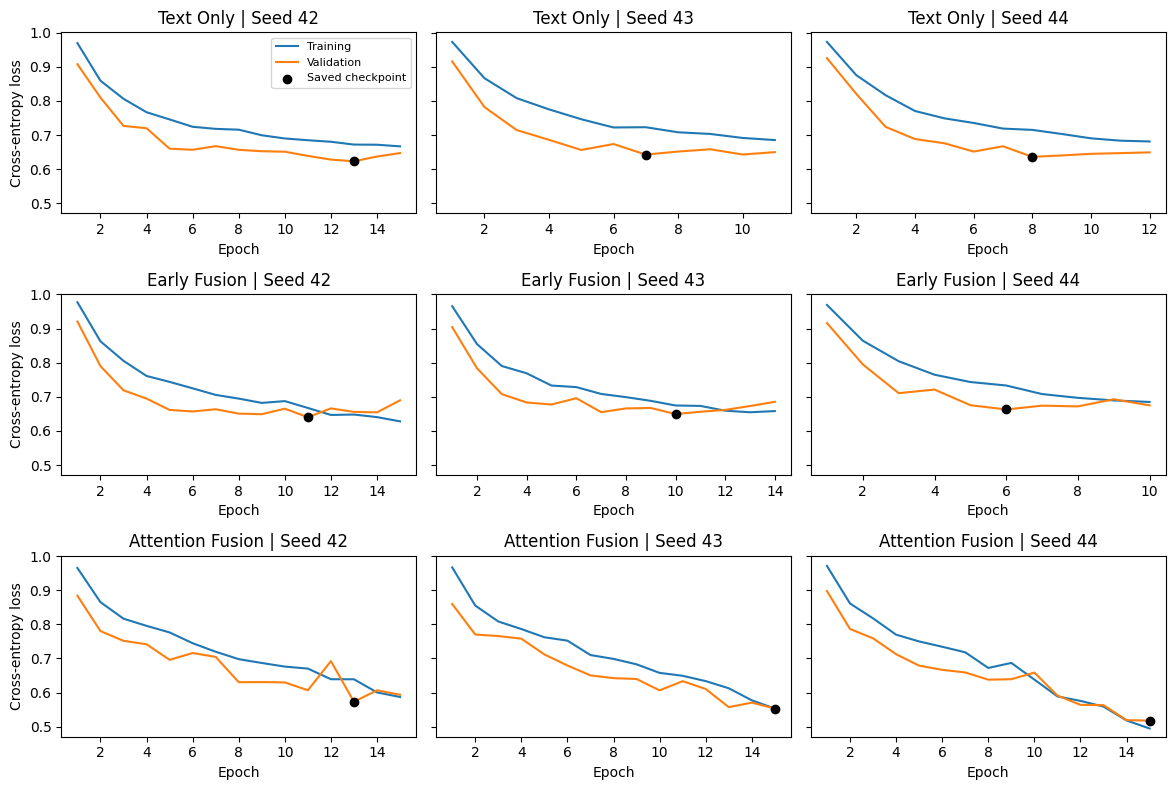

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    len(model_names), len(seeds),
    figsize=(12, 8),
    sharey=True,
)

# Make one plot for each model and starting seed.
for row, name in enumerate(model_names):
    for col, seed in enumerate(seeds):
        ax = axes[row, col]
        run = history[(history["model"] == name) & (history["seed"] == seed)]

        # Lower loss means the model scored the correct answers better.
        ax.plot(run["epoch"], run["train_loss"], label="Training")
        ax.plot(run["epoch"], run["validation_loss"], label="Validation")

        # Mark the epoch with the lowest validation loss.
        best = run.loc[run["validation_loss"].idxmin()]
        ax.scatter(best["epoch"], best["validation_loss"], color="black",
                   label="Saved checkpoint", zorder=3)

        ax.set_title(f"{name.replace('_', ' ').title()} | Seed {seed}")
        ax.set_xlabel("Epoch")
        if col == 0:
            ax.set_ylabel("Cross-entropy loss")

axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [ ]:
# Turn the test images and text into the same features used for training.
vit.to(device)
bert.to(device)
features["test"] = extract_features(clean_data["test"])
vit.cpu()
bert.cpu()
torch.cuda.empty_cache()

test_data = features["test"]
test_answers = test_data["labels"]
test_results = []
test_probabilities = {}

# Check how often we would be right if we guessed randomly.
choice_counts = test_data["option_mask"].sum(dim=1).float()
print(f"Random guessing accuracy: {(1 / choice_counts).mean().item():.2%}")

for name in model_names:
    for seed in seeds:
        # Load the saved model. We are testing it, not training it again.
        model = ScienceQAModel(name).to(device)
        model.load_state_dict(checkpoints[name, seed])
        model.eval()

        probabilities = []
        total_loss = 0.0

        with torch.inference_mode():
            for start in range(0, len(test_answers), batch_size):
                stop = start + batch_size

                # Read one small batch at a time to save GPU memory.
                batch = {
                    key: test_data[key][start:stop].to(device)
                    for key in fields[name]
                }

                scores = model(batch)
                total_loss += F.cross_entropy(
                    scores, batch["labels"], reduction="sum"
                ).item()

                # Save the probabilities for later error analysis.
                probabilities.append(scores.softmax(dim=1).cpu())

        probabilities = torch.cat(probabilities)
        test_probabilities[name, seed] = probabilities

        # Compare the model's top choice with the correct answer.
        predictions = probabilities.argmax(dim=1)
        accuracy = (predictions == test_answers).float().mean().item()

        test_results.append({
            "model": name,
            "seed": seed,
            "accuracy_pct": 100 * accuracy,
            "test_loss": total_loss / len(test_answers),
        })

test_results = pd.DataFrame(test_results)

# Show every run, then summarise the three runs for each model.
print("\nResults for each seed:")
display(test_results.round(3))

test_summary = test_results.groupby("model", sort=False).agg(
    mean_accuracy_pct=("accuracy_pct", "mean"),
    accuracy_sd_pp=("accuracy_pct", "std"),
    mean_test_loss=("test_loss", "mean"),
)

print("\nSummary across seeds:")
display(test_summary.round(3))

Extracting features:   0%|          | 0/132 [00:00<?, ?it/s]

Option pairs truncated: 4
Random guessing accuracy: 29.77%

Results for each seed:


,model,seed,accuracy_pct,test_loss
0,text_only,42,62.952,0.689
1,text_only,43,63.143,0.685
2,text_only,44,63.429,0.683
3,early_fusion,42,64.381,0.669
4,early_fusion,43,64.190,0.682
5,early_fusion,44,63.238,0.693
6,attention_fusion,42,71.048,0.618
7,attention_fusion,43,74.667,0.582
8,attention_fusion,44,77.524,0.506



Summary across seeds:


,mean_accuracy_pct,accuracy_sd_pp,mean_test_loss
model,,,
text_only,63.175,0.240,0.686
early_fusion,63.937,0.612,0.681
attention_fusion,74.413,3.246,0.569


In [ ]:
import numpy as np

# Give questions with identical images the same group number.
image_keys = []
for row in clean_data["test"]:
    image = ImageOps.exif_transpose(row["image"]).convert("RGB")
    image_keys.append((image.size, sha256(image.tobytes()).hexdigest()))

image_groups, unique_images = pd.factorize(image_keys)
group_sizes = np.bincount(image_groups)
print("Test images:", len(unique_images))

# Find the fraction of seeds that answered each question correctly.
correct = {}
for name in model_names:
    runs = [
        (test_probabilities[name, seed].argmax(dim=1) == test_answers).numpy()
        for seed in seeds
    ]
    correct[name] = np.mean(runs, axis=0)

# Make 2,000 new samples by drawing whole image groups with replacement.
rng = np.random.default_rng(42)
samples = rng.integers(
    len(unique_images), size=(2000, len(unique_images))
)
sample_sizes = group_sizes[samples].sum(axis=1)

rows = []
for name in ["early_fusion", "attention_fusion"]:
    # Positive values mean fusion answered more questions correctly.
    gain = correct[name] - correct["text_only"]
    gain_by_image = np.bincount(image_groups, weights=gain)

    # Compare both models on the same sampled questions.
    sampled_gains = 100 * gain_by_image[samples].sum(axis=1) / sample_sizes
    low, high = np.percentile(sampled_gains, [2.5, 97.5])

    rows.append({
        "model": name,
        "gain_over_text_pp": 100 * gain.mean(),
        "95% CI lower_pp": low,
        "95% CI upper_pp": high,
    })

gain_summary = pd.DataFrame(rows)
display(gain_summary.round(2))

Test images: 1033


/tmp/ipykernel_5774/1213411676.py:9: FutureWarning: factorize with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  image_groups, unique_images = pd.factorize(image_keys)


,model,gain_over_text_pp,95% CI lower_pp,95% CI upper_pp
0,early_fusion,0.76,-0.92,2.34
1,attention_fusion,11.24,9.17,13.20


In [ ]:
confidence_rows = []
subject_rows = []

for name in model_names:
    for seed in seeds:
        # The model's confidence is the probability of its chosen answer.
        confidence, prediction = test_probabilities[name, seed].max(dim=1)
        is_correct = prediction == test_answers

        # Count wrong answers the model gave at least 80% confidence.
        sure = confidence >= 0.80
        confidence_rows.append({
            "model": name,
            "mean_confidence_pct": 100 * confidence.mean().item(),
            "accuracy_pct": 100 * is_correct.float().mean().item(),
            "high_confidence_wrong": (sure & ~is_correct).sum().item(),
        })

    # Use the average correctness across seeds from Section 8.
    for subject in sorted(set(clean_data["test"]["subject"])):
        mask = np.array(clean_data["test"]["subject"]) == subject
        subject_rows.append({
            "model": name,
            "subject": subject,
            "questions": mask.sum(),
            "accuracy_pct": 100 * correct[name][mask].mean(),
        })

# Average the confidence results across the three runs.
confidence_summary = pd.DataFrame(confidence_rows).groupby("model").mean()
print("Confidence and errors (average per run):")
display(confidence_summary.round(2))

# Show how many test questions each subject result is based on.
subject_summary = pd.DataFrame(subject_rows)
print("Test accuracy by subject:")
display(subject_summary.round(2))

Confidence and errors (average per run):


,mean_confidence_pct,accuracy_pct,high_confidence_wrong
model,,,
attention_fusion,76.99,74.41,32.00
early_fusion,65.58,63.94,13.33
text_only,66.03,63.17,12.33


Test accuracy by subject:


,model,subject,questions,accuracy_pct
0,text_only,language science,26,41.03
1,text_only,natural science,309,57.50
2,text_only,social science,715,66.43
3,early_fusion,language science,26,53.85
4,early_fusion,natural science,309,59.87
5,early_fusion,social science,715,66.06
6,attention_fusion,language science,26,50.00
7,attention_fusion,natural science,309,63.00
8,attention_fusion,social science,715,80.23


In [ ]:
# Shuffle the images in a repeatable way.
shuffled = np.random.default_rng(42).permutation(len(test_answers))

# Leave out questions that happened to get the same image.
# Compare both scores on exactly the same remaining questions.
changed = image_groups != image_groups[shuffled]
question_ids = torch.from_numpy(np.flatnonzero(changed))
shuffled = torch.from_numpy(shuffled)

print("Questions given a different image:", len(question_ids))

shuffle_rows = []

for name in ["early_fusion", "attention_fusion"]:
    for seed in seeds:
        # Load the trained model without changing its weights.
        model = ScienceQAModel(name).to(device)
        model.load_state_dict(checkpoints[name, seed])
        model.eval()

        # Count correct answers with the original images.
        original = test_probabilities[name, seed][question_ids].argmax(dim=1)
        original_correct = (original == test_answers[question_ids]).sum().item()
        shuffled_correct = 0

        with torch.inference_mode():
            for ids in question_ids.split(batch_size):
                batch = {}

                for key in fields[name]:
                    # Swap image features and their masks together.
                    # Keep the original text and correct answers.
                    source = shuffled[ids] if key in {
                        "pooled_images", "patches", "patch_mask"
                    } else ids
                    batch[key] = test_data[key][source].to(device)

                predictions = model(batch).argmax(dim=1)
                shuffled_correct += (predictions == batch["labels"]).sum().item()

        shuffle_rows.append({
            "model": name,
            "seed": seed,
            "original_accuracy_pct": 100 * original_correct / len(question_ids),
            "shuffled_accuracy_pct": 100 * shuffled_correct / len(question_ids),
            "accuracy_drop_pp": 100 * (
                original_correct - shuffled_correct
            ) / len(question_ids),
        })

# Show the average across the three trained runs.
shuffle_results = pd.DataFrame(shuffle_rows)
shuffle_summary = shuffle_results.drop(columns="seed").groupby("model").mean()
display(shuffle_summary.round(2))

Questions given a different image: 1048


,original_accuracy_pct,shuffled_accuracy_pct,accuracy_drop_pp
model,,,
attention_fusion,74.46,55.85,18.61
early_fusion,64.06,62.88,1.18


In [ ]:
speed_rows = []

for name in model_names:
    # Use seed 42 for every model. The other seeds have the same model size.
    model = ScienceQAModel(name).to(device)
    model.load_state_dict(checkpoints[name, 42])
    model.eval()

    # These are the inputs needed to make a prediction.
    input_keys = [key for key in fields[name] if key != "labels"]
    times = []

    with torch.inference_mode():
        for repeat in range(6):
            # Wait for any earlier GPU work before starting the timer.
            if device.type == "cuda":
                torch.cuda.synchronize()
            start_time = time.perf_counter()

            for start in range(0, len(test_answers), batch_size):
                stop = start + batch_size
                batch = {
                    key: test_data[key][start:stop].to(device)
                    for key in input_keys
                }

                # Pick the highest-scoring answer and bring it back to the CPU.
                predictions = model(batch).argmax(dim=1).cpu()

            if device.type == "cuda":
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - start_time

            # Skip the first pass so the GPU has time to warm up.
            if repeat > 0:
                times.append(elapsed)

    speed_rows.append({
        "model": name,
        "parameters": sum(p.numel() for p in model.parameters()),
        "ms_per_question": 1000 * np.median(times) / len(test_answers),
        "mean_training_seconds": validation_results.loc[
            validation_results["model"] == name, "training_seconds"
        ].mean(),
    })

speed_summary = pd.DataFrame(speed_rows)
display(speed_summary.round(4))

,model,parameters,ms_per_question,mean_training_seconds
0,text_only,115073,0.0188,10.8187
1,early_fusion,229889,0.0262,7.8942
2,attention_fusion,279553,0.1236,46.6764


Test accuracy by grade (%):


,grade,questions,text_only,early_fusion,attention_fusion
0,grade1,2,0.00,0.00,16.67
1,grade2,53,55.97,64.78,63.52
2,grade3,209,69.38,71.45,75.44
3,grade4,218,69.88,70.03,73.39
4,grade5,227,68.14,67.25,75.33
5,grade6,103,63.11,63.75,80.58
6,grade7,118,52.82,50.28,77.40
7,grade8,120,45.28,47.78,70.28



Illustrative mistake:
Question: What is the capital of Georgia?
1. Augusta
2. Lincoln
3. Jackson
4. Atlanta
Correct option: 4
Predicted option: 1
Model confidence: 100.0%


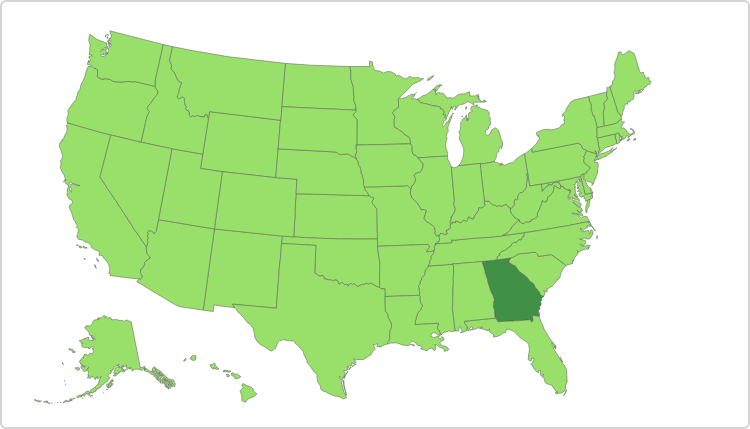

In [ ]:
# Compare accuracy by grade and show how many questions each grade has.
grades = np.array(clean_data["test"]["grade"])
grade_rows = []

for grade in sorted(set(grades)):
    in_grade = grades == grade
    row = {"grade": grade, "questions": int(in_grade.sum())}

    # Use the average correctness across the three seeds from Section 8.
    for name in model_names:
        row[name] = 100 * correct[name][in_grade].mean()

    grade_rows.append(row)

print("Test accuracy by grade (%):")
grade_summary = pd.DataFrame(grade_rows)
display(grade_summary.round(2))

# Use the first seed. Find its most confident wrong answer.
confidence, prediction = test_probabilities["attention_fusion", seeds[0]].max(dim=1)
wrong = prediction != test_answers

if wrong.any():
    i = confidence.masked_fill(~wrong, -1).argmax().item()
    example = clean_data["test"][i]

    print("\nIllustrative mistake:")
    print("Question:", example["question"])

    if example["hint"]:
        print("Hint:", example["hint"])

    for option, choice in enumerate(example["choices"], start=1):
        print(f"{option}. {choice}")

    print("Correct option:", test_answers[i].item() + 1)
    print("Predicted option:", prediction[i].item() + 1)
    print(f"Model confidence: {confidence[i].item():.1%}")
    display(example["image"])

**Limitations and ethics**

Attention fusion performed better than text only in most grade groups, with the largest gains in grades 7 and 8. However, the test set was uneven: grade 1 had only two questions, and social science accounted for 715 of the 1,050 test questions. The overall result therefore reflects social science more heavily than other subjects. Reporting accuracy by grade and subject makes these differences visible, but it does not establish fairness across student populations.

One example shows why confidence needs to be interpreted carefully. When asked for the capital of Georgia, the model selected **Augusta** instead of **Atlanta**, with confidence displayed as 100.0% after rounding. The map identifies the state but does not label its capital, so the task also requires factual knowledge. This example shows that the model can be confidently wrong; it does not reveal why it chose Augusta. Across the three runs, attention fusion averaged 32 wrong answers with at least 80% confidence.

The split checks removed exact image and text overlap, but similar diagrams and reworded questions may still occur across splits. Resizing diagrams to 224 × 224 pixels may also obscure small labels. Future work could check for near-duplicates, test higher image resolutions, and assess confidence on a more balanced set of questions. Until then, the model is best treated as a research prototype, with human review before its answers are used in education.

,model,mean_accuracy_pct,accuracy_sd_pp,mean_test_loss,parameters,ms_per_question,mean_training_seconds
0,text_only,63.1746,0.2397,0.6858,115073,0.0188,10.8187
1,early_fusion,63.9365,0.6123,0.6813,229889,0.0262,7.8942
2,attention_fusion,74.4127,3.2456,0.5686,279553,0.1236,46.6764


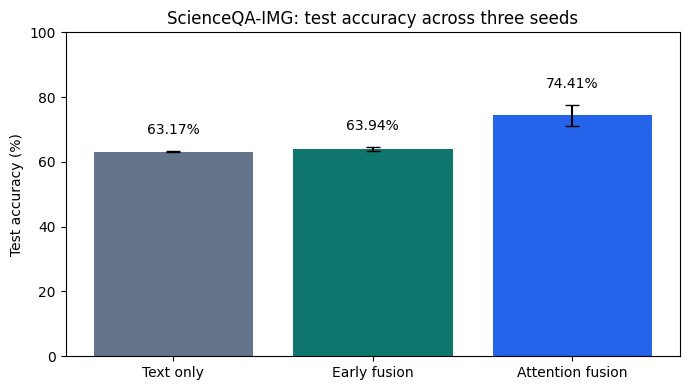

In [ ]:
# Put the test results and speed measurements in one table.
final_results = test_summary.reset_index().merge(speed_summary, on="model")
display(final_results.round(4))

# Save the full table for the report and GitHub repository.
final_results.to_csv("final_results.csv", index=False)

# Compare average test accuracy. The bars show variation across the three seeds.
labels = ["Text only", "Early fusion", "Attention fusion"]
fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    labels,
    final_results["mean_accuracy_pct"],
    yerr=final_results["accuracy_sd_pp"],
    capsize=5,
    color=["#64748b", "#0f766e", "#2563eb"],
)

ax.bar_label(bars, fmt="%.2f%%", padding=10)
ax.set_ylim(0, 100)
ax.set_ylabel("Test accuracy (%)")
ax.set_title("ScienceQA-IMG: test accuracy across three seeds")

# Save a copy of the figure for the report or slides.
fig.tight_layout()
fig.savefig("test_accuracy.png", dpi=200)
plt.show()

Attention fusion reached 74.41% test accuracy, an 11.24 percentage point gain over text only (95% bootstrap interval: 9.17–13.20 points). Early fusion’s gain was only 0.76 points, and its interval included zero. Attention fusion also took 4.7× as long as early fusion for cached-feature inference, excluding feature extraction.